# **1. PHÂN NHÓM KHÁCH HÀNG MỤC TIÊU**

CosmeticWorld – một chuỗi bán lẻ mỹ phẩm và sản phẩm chăm sóc cơ thể toàn cầu. Sau 4 năm hoạt động (2020 - 2023), hệ thống đã ghi nhận hơn 50.000 giao dịch.
Giám đốc Marketing đang lên kế hoạch cho chiến dịch "New Year Rejuvenation 2024". Tuy nhiên, sếp không muốn gửi email khuyến mãi tràn lan vì chi phí cao và gây phiền hà cho khách hàng. Sếp yêu cầu bạn: "Hãy phân loại toàn bộ tệp khách hàng dựa trên hành vi mua sắm thực tế của họ để chúng ta có chiến lược tiếp cận thông minh hơn!"


## Import Library & Import Data

In [ ]:
# Data Processing
import pandas as pd
import numpy as np

# Data Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Datetime Standardize
import datetime

In [ ]:
import sys
import matplotlib

print(f"Python version: {sys.version.split()[0]}")
print(f"pandas version: {pd.__version__}")
print(f"matplotlib version: {matplotlib.__version__}")
print(f"numpy version: {np.__version__}")

Python version: 3.13.18
pandas version: 2.2.3
matplotlib version: 3.10.0
numpy version: 2.4.6


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
product = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/AdventureWorks_Products.csv')
sales_2015 = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/AdventureWorks_Sales_2015.csv')
sales_2016 = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/AdventureWorks_Sales_2016.csv')
sales_2017 = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/AdventureWorks_Sales_2017.csv')

In [ ]:
product.head(3)

,ProductKey,ProductSubcategoryKey,ProductSKU,ProductName,ModelName,ProductDescription,ProductColor,ProductSize,ProductStyle,ProductCost,ProductPrice
0,214,31,HL-U509-R,"Sport-100 Helmet, Red",Sport-100,"Universal fit, well-vented, lightweight , snap...",Red,0,0,13.0863,34.9900
1,215,31,HL-U509,"Sport-100 Helmet, Black",Sport-100,"Universal fit, well-vented, lightweight , snap...",Black,0,0,12.0278,33.6442
2,218,23,SO-B909-M,"Mountain Bike Socks, M",Mountain Bike Socks,Combination of natural and synthetic fibers st...,White,M,U,3.3963,9.5000


In [ ]:
sales = pd.concat([sales_2015, sales_2016, sales_2017], ignore_index = True)
sales.head(5)

,OrderDate,StockDate,OrderNumber,ProductKey,CustomerKey,TerritoryKey,OrderLineItem,OrderQuantity
0,1/1/2015,9/21/2001,SO45080,332,14657,1,1,1
1,1/1/2015,12/5/2001,SO45079,312,29255,4,1,1
2,1/1/2015,10/29/2001,SO45082,350,11455,9,1,1
3,1/1/2015,11/16/2001,SO45081,338,26782,6,1,1
4,1/2/2015,12/15/2001,SO45083,312,14947,10,1,1


In [ ]:
# R = OrderDate = ngày mua --> Ngày mua gần nhất so với hiện tại của từng KH --> max
# F = OrderNumber = số lượng đơn mua --> Tần suất mua trong 1 khoảng tgi --> count_distinct
# M = số tiền mua trong 1 khoảng tgi --> sum(revenue)
# tính theo customer = CustomerKey
# 4 cột để vẽ RFM = CustomerKey + Tgi đặt đơn + mã đơn + số tiền

## Data Checking

In [ ]:
# Check metadata

In [ ]:
# Check data types

In [ ]:
# Check dup

In [ ]:
# Check NA
# Check outliers

In [ ]:
# @title
def check_dataframe(df: pd.DataFrame, outlier_threshold: float = 1.5) -> None:
    """Kiểm tra tổng thể một DataFrame bao gồm:

    1. Metadata (df.info)
    2. Data types
    3. Duplicate rows
    4. Missing values (NA)
    5. Outliers (phương pháp IQR cho biến định lượng)
    """
    print("=" * 60)
    print("1. DF METADATA & DATA TYPES")
    print("=" * 60)
    print(f"- Shape: {df.shape[0]} hàng x {df.shape[1]} cột\n")

    # Bảng tổng hợp Type, Missing values và Unique values
    type_na_df = pd.DataFrame(
        {
            "Data Type": df.dtypes,
            "Non-Null Count": df.notnull().sum(),
            "Null Count": df.isnull().sum(),
            "Null Ratio (%)": (df.isnull().sum() / len(df) * 100).round(2),
            "N-Unique": df.nunique(),
        }
    )
    print(type_na_df)

    print("\n" + "=" * 60)
    print("2. DUPLICATE CHECK")
    print("=" * 60)
    num_duplicates = df.duplicated().sum()
    dup_percent = (num_duplicates / len(df)) * 100
    print(
        f"- Số dòng trùng lặp hoàn toàn: {num_duplicates} ({dup_percent:.2f}%)"
    )

    print("\n" + "=" * 60)
    print("3. MISSING VALUES (NA) SUMMARY")
    print("=" * 60)
    cols_with_na = type_na_df[type_na_df["Null Count"] > 0]
    if cols_with_na.empty:
        print("- Không có cột nào bị thiếu dữ liệu (NA).")
    else:
        print(cols_with_na[["Null Count", "Null Ratio (%)"]])

    print("\n" + "=" * 60)
    print("4. OUTLIERS CHECK (IQR Method)")
    print("=" * 60)
    # Lọc các cột dạng số (định lượng)
    num_cols = df.select_dtypes(include=[np.number]).columns

    if len(num_cols) == 0:
        print("- Không tìm thấy cột dạng số để kiểm tra outlier.")
    else:
        outlier_summary = []
        for col in num_cols:
            # Bỏ qua giá trị NA khi tính quantile
            q1 = df[col].quantile(0.25)
            q3 = df[col].quantile(0.75)
            iqr = q3 - q1

            lower_bound = q1 - outlier_threshold * iqr
            upper_bound = q3 + outlier_threshold * iqr

            outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)][
                col
            ]
            count_outliers = len(outliers)

            if count_outliers > 0:
                outlier_summary.append(
                    {
                        "Column": col,
                        "Outlier Count": count_outliers,
                        "Outlier Ratio (%)": round(
                            (count_outliers / len(df)) * 100, 2
                        ),
                        "Lower Bound": round(lower_bound, 2),
                        "Upper Bound": round(upper_bound, 2),
                        "Min Value": round(df[col].min(), 2),
                        "Max Value": round(df[col].max(), 2),
                    }
                )

        if outlier_summary:
            outlier_df = pd.DataFrame(outlier_summary).set_index("Column")
            print(outlier_df)
        else:
            print("- Không phát hiện outlier nào ở các cột dạng số.")

    print("\n" + "=" * 60)

In [ ]:
# Check all
check_dataframe(sales)

1. DF METADATA & DATA TYPES
- Shape: 56046 hàng x 8 cột

              Data Type  Non-Null Count  Null Count  Null Ratio (%)  N-Unique
OrderDate        object           56046           0             0.0       911
StockDate        object           56046           0             0.0      1001
OrderNumber      object           56046           0             0.0     25164
ProductKey        int64           56046           0             0.0       130
CustomerKey       int64           56046           0             0.0     17416
TerritoryKey      int64           56046           0             0.0        10
OrderLineItem     int64           56046           0             0.0         8
OrderQuantity     int64           56046           0             0.0         3

2. DUPLICATE CHECK
- Số dòng trùng lặp hoàn toàn: 0 (0.00%)

3. MISSING VALUES (NA) SUMMARY
- Không có cột nào bị thiếu dữ liệu (NA).

4. OUTLIERS CHECK (IQR Method)
               Outlier Count  Outlier Ratio (%)  Lower Bound  Upper Bound 

## Data Preprocessing / Wrangling

In [ ]:
# Solve data types

In [ ]:
# Solve dup

In [ ]:
# Solve NA

In [ ]:
# Solve outliers

## Exploratory Data Analysis

In [ ]:
# R = OrderDate = ngày mua --> Ngày mua gần nhất so với hiện tại của từng KH --> max
# F = OrderNumber = số lượng đơn mua --> Tần suất mua trong 1 khoảng tgi --> count_distinct
# M = số tiền mua trong 1 khoảng tgi --> sum(revenue)
# tính theo customer = CustomerKey
# 4 cột để vẽ RFM = CustomerKey + Tgi đặt đơn + mã đơn + số tiền

In [ ]:
df = sales.merge(product, on = 'ProductKey', how = 'left')[['OrderDate','OrderNumber','OrderQuantity','ProductPrice','CustomerKey']]
df.head()

,OrderDate,OrderNumber,OrderQuantity,ProductPrice,CustomerKey
0,1/1/2015,SO45080,1,699.0982,14657
1,1/1/2015,SO45079,1,3578.2700,29255
2,1/1/2015,SO45082,1,3374.9900,11455
3,1/1/2015,SO45081,1,699.0982,26782
4,1/2/2015,SO45083,1,3578.2700,14947


In [ ]:
df['OrderDate'] = pd.to_datetime(df['OrderDate'], format='%m/%d/%Y')
df['Revenue'] = df['OrderQuantity'] * df['ProductPrice']

In [ ]:
# Calculate Recency, Frequency, Monetary
current_date = df['OrderDate'].max() + datetime.timedelta(days=1)

df_rfm = df.groupby('CustomerKey').agg(
    Recency=('OrderDate', lambda date: (current_date - date.max()).days),
    Frequency=('OrderNumber', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()

In [ ]:
df_rfm.head()

,CustomerKey,Recency,Frequency,Monetary
0,11000,239,2,4656.3896
1,11001,19,2,2821.2122
2,11002,308,2,4466.8124
3,11003,232,2,4532.9866
4,11004,241,2,4568.0838


In [ ]:
df_rfm['R_Score'] = pd.qcut(df_rfm['Recency'], 5, labels = [5, 4, 3, 2, 1])

df_rfm['R_Score'].unique()

[2, 5, 1, 4, 3]
Categories (5, int64): [5 < 4 < 3 < 2 < 1]

In [ ]:
df_rfm['M_Score'] = pd.qcut(df_rfm['Monetary'], 5, labels = [1,2,3,4,5])

df_rfm['M_Score'].unique()

[5, 2, 1, 3, 4]
Categories (5, int64): [1 < 2 < 3 < 4 < 5]

In [ ]:
#khi chặt dữ liệu, nó tập trung chủ yếu về 1 phía
# ecomerce: 1 số KH họ chỉ mua 1-2 lần thôi
# do đó cần vẽ biểu đồ để xem F đa phần nằm ở đâu
df_freq = df_rfm[['Frequency']].drop_duplicates().sort_values(by = 'Frequency',ascending = True).reset_index(drop = True)
df_freq['F_Score'] = pd.qcut(df_freq['Frequency'], 5, labels = [1,2,3,4,5], duplicates = 'drop')

df_freq['F_Score'].unique()

[1, 2, 3, 4, 5]
Categories (5, int64): [1 < 2 < 3 < 4 < 5]

In [ ]:
df_rfm_final = df_rfm.merge(df_freq, on = 'Frequency', how = 'inner')[['CustomerKey', 'R_Score', 'F_Score', 'M_Score']]
df_rfm_final['RFM_Score']= df_rfm_final['R_Score'].astype(str) + df_rfm_final['F_Score'].astype(str) + df_rfm_final['M_Score'].astype(str)
df_rfm_final['RFM_Score'] = df_rfm_final['RFM_Score'].astype(int)
df_rfm_final

,CustomerKey,R_Score,F_Score,M_Score,RFM_Score
0,11000,2,1,5,215
1,11001,5,1,5,515
2,11002,1,1,5,115
3,11003,2,1,5,215
4,11004,2,1,5,215
...,...,...,...,...,...
17411,29479,1,1,4,114
17412,29480,3,1,4,314
17413,29481,1,1,5,115
17414,29482,1,1,4,114


In [ ]:
# @title
df_rfm_final['RFM_Segment'] = 'Other'  # Default label for rows not matching any segment

# Ctrl + Shift + L

# Champions
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([555, 554, 544, 545, 454, 455, 445]), 'RFM_Segment'] = 'Champions'

# Loyal
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([543, 444, 435, 355, 354, 345, 344, 335]), 'RFM_Segment'] = 'Loyal'

# Potential Loyalist
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([553, 551, 552, 541, 542, 533, 532, 531, 452, 451
                                                 , 442, 441, 431, 453, 433, 432, 423, 353, 352
                                                 , 351, 342, 341, 333, 323]), 'RFM_Segment'] = 'Potential Loyalist'

# Promising
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([525, 524, 523, 522, 521, 515, 514, 513
                                                 , 425, 424, 413, 414, 415, 315, 314, 313]), 'RFM_Segment'] = 'Promising'

# New Customers
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([512, 511, 422, 421, 412, 411, 311]), 'RFM_Segment'] = 'New Customers'

# Need Attention
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([535, 534, 443, 434, 343, 334, 325, 324]), 'RFM_Segment'] = 'Need Attention'

# About To Sleep
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([331, 321, 312, 221, 213, 231, 241, 251]), 'RFM_Segment'] = 'About To Sleep'

# At Risk
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([255, 254, 245, 244, 253, 252, 243, 242, 235
                                                 , 234, 225, 224, 153, 152, 145, 143, 142
                                                 , 135, 134, 133, 125, 124]), 'RFM_Segment'] = 'At Risk'

# Cannot Lose Them
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([155, 154, 144, 214, 215, 115, 114, 113]), 'RFM_Segment'] = 'Cannot Lose Them'

# Hibernating customers
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([332, 322, 233, 232, 223, 222, 132, 123, 122, 212, 211]), 'RFM_Segment'] = 'Hibernating customers'

# Lost customers
df_rfm_final.loc[df_rfm_final['RFM_Score'].isin([111, 112, 121, 131, 141, 151]), 'RFM_Segment'] = 'Lost customers'

# Display the DataFrame with the new RFM_Segment column
df_rfm_final

,CustomerKey,R_Score,F_Score,M_Score,RFM_Score,RFM_Segment
0,11000,2,1,5,215,Cannot Lose Them
1,11001,5,1,5,515,Promising
2,11002,1,1,5,115,Cannot Lose Them
3,11003,2,1,5,215,Cannot Lose Them
4,11004,2,1,5,215,Cannot Lose Them
...,...,...,...,...,...,...
17411,29479,1,1,4,114,Cannot Lose Them
17412,29480,3,1,4,314,Promising
17413,29481,1,1,5,115,Cannot Lose Them
17414,29482,1,1,4,114,Cannot Lose Them


In [ ]:
df_after_rfm = df.merge(df_rfm_final, on = 'CustomerKey', how = 'inner')
treemap_input = df_after_rfm.groupby(by = 'RFM_Segment', as_index = True).agg(count_customer = ('CustomerKey', 'nunique'), revenue = ('Revenue','sum'))\
  .sort_values(by = 'revenue', ascending = False).reset_index()
treemap_input

,RFM_Segment,count_customer,revenue
0,Promising,6385,1.528950e+07
1,Cannot Lose Them,3264,8.629204e+06
2,About To Sleep,1449,3.964274e+05
3,New Customers,3238,1.817195e+05
4,Need Attention,16,1.354243e+05
5,Hibernating customers,1505,9.052751e+04
6,Lost customers,1477,8.677304e+04
7,At Risk,4,4.133886e+04
8,Champions,16,2.422403e+04
9,Potential Loyalist,55,2.245622e+04


##Data Visualization

In [ ]:
import plotly.express as px

# Create a Treemap for Customer Count
fig = px.treemap(treemap_input, path=['RFM_Segment'], values='count_customer', title='RFM Segments - Customer Count Treemap')

# Show the plot
fig.show()

# Create a Treemap for total revenue
fig_rev = px.treemap(treemap_input, path=['RFM_Segment'], values='revenue', title='RFM Segments - Total Revenue Treemap')

# Show the revenue plot
fig_rev.show()

# **2. CHÂN DUNG KHÁCH HÀNG**

Sau thành công của chiến dịch RFM, Ban Giám đốc CosmeticWorld muốn bạn thực hiện một bản báo cáo chuyên sâu hơn. Sếp đặt ra một câu hỏi hóc búa: "Chúng ta biết ai là người mua nhiều nhất, nhưng chúng ta chưa biết Họ là ai? Họ ở đâu? Và họ mua cái gì?".


##Import data

In [ ]:
customer = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/Customer.csv')
ecom_sales = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/EcomSales.csv')
product = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/Product.csv')
region = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/RFM/Region.csv')

##Data checking

In [ ]:
check_dataframe(ecom_sales)

1. DF METADATA & DATA TYPES
- Shape: 51290 hàng x 11 cột

            Data Type  Non-Null Count  Null Count  Null Ratio (%)  N-Unique
RowID           int64           51290           0             0.0     51290
OrderID        object           51290           0             0.0     25728
OrderDate      object           51290           0             0.0      1430
CustomerID     object           51290           0             0.0     17415
Segment        object           51290           0             0.0         3
RegionCode     object           51290           0             0.0      3829
ProductCode    object           51290           0             0.0      3578
Quantity        int64           51290           0             0.0        20
Sales           int64           51290           0             0.0       997
Discount      float64           51290           0             0.0        27
Profit        float64           51290           0             0.0      3822

2. DUPLICATE CHECK
- Số dòng 

In [ ]:
check_dataframe(customer)

1. DF METADATA & DATA TYPES
- Shape: 17415 hàng x 11 cột

               Data Type  Non-Null Count  Null Count  Null Ratio (%)  N-Unique
CustomerID        object           17415           0            0.00     17415
FirstName         object           17415           0            0.00       663
LastName          object           17415           0            0.00       370
BirthDate         object           17415           0            0.00      9893
MaritalStatus     object           17415           0            0.00         2
Gender            object           17291         124            0.71         2
EmailAddress      object           17415           0            0.00     17415
AnnualIncome       int64           17415           0            0.00        16
EducationLevel    object           17415           0            0.00         5
Occupation        object           17415           0            0.00         5
HomeOwner         object           17415           0            0.00     

In [ ]:
#nối bảng
df = customer.merge(ecom_sales, on ='CustomerID', how = 'left')
df = df.merge(product, on = 'ProductCode', how = 'left')
df = df.merge(region, on = 'RegionCode', how = 'left')
df.head()

,CustomerID,FirstName,LastName,BirthDate,MaritalStatus,Gender,EmailAddress,AnnualIncome,EducationLevel,Occupation,...,Product,Category,Subcategory,City,State,Country,Countrylatitude,Countrylongitude,Region,Market
0,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,...,Soap & Glory Endless Glove Moisturizing Hand C...,Body care,"bath oils, bubbles and soaks",NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,...,Eucerin Advanced Repair Cream,Body care,Nail care products,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific
3,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,...,Diptyque French Cade Lavender Candle,Home and Accessories,"candles, sprays, diffusers",Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific
4,TH-211151,Jon,Huang,6/18/1962,M,M,jon24@hotmail.com,90000,Bachelors,Professional,...,NARS Single Eyeshadow Persia Matte Paprika,Make up,Eye shadows and pencils,Jalalabad,Nangarhar,Afghanistan,33.93911,67.709953,Southern Asia,Asia Pacific


## Data Preprocessing / Wrangling

In [ ]:
# Solve data types
df['BirthDate'] = pd.to_datetime(df['BirthDate'])
df['OrderDate'] = pd.to_datetime(df['OrderDate'])

##EDA

In [ ]:
#Tính doanh thu thực tế
df['Revenue'] = df['Sales'] * (1 - df['Discount'])

In [ ]:
# R = orderID
# F = orderdate
# M = revenue
# group theo CustomerID

In [ ]:
#Tính R, F, M
current_date = datetime.datetime.now()

df_rfm = df.groupby('CustomerID').agg(
    Recency=('OrderDate', lambda date: (current_date - date.max()).days),
    Frequency=('OrderID', 'nunique'),
    Monetary=('Revenue', 'sum')
).reset_index()
df_rfm

,CustomerID,Recency,Frequency,Monetary
0,AA-10315102,1403,2,506.800
1,AA-10315120,2004,1,63.000
2,AA-10315139,1194,4,596.600
3,AA-103151402,1229,2,195.800
4,AA-103151404,1863,2,213.600
...,...,...,...,...
17410,ZD-2192548,1795,3,164.200
17411,ZD-2192564,2454,1,152.000
17412,ZD-219257,2243,1,111.600
17413,ZD-2192582,1241,2,126.354


In [ ]:
#score
df_rfm['R_Score'] = pd.qcut(df_rfm['Recency'], 5, labels = [5, 4, 3, 2, 1])

df_rfm['R_Score'].unique()

[3, 1, 4, 2, 5]
Categories (5, int64): [5 < 4 < 3 < 2 < 1]

In [ ]:
df_rfm['M_Score'] = pd.qcut(df_rfm['Monetary'], 5, labels = [1,2,3,4,5])

df_rfm['M_Score'].unique()

[5, 2, 3, 4, 1]
Categories (5, int64): [1 < 2 < 3 < 4 < 5]

In [ ]:
#Frequency: dữ liệu tần suất thường bị lệch. remove duplicate rồi mới score
df_f = df_rfm[['Frequency']].drop_duplicates().sort_values('Frequency')
df_f['F_Score'] = pd.qcut(df_f['Frequency'], q=5,labels=[1, 2, 3, 4, 5], duplicates='drop')
df_f['F_Score'].unique()

[1, 2, 3, 4, 5]
Categories (5, int64): [1 < 2 < 3 < 4 < 5]

In [ ]:
df_rfm = df_rfm.merge(df_f, on = 'Frequency', how = 'left')
df_rfm.head()

,CustomerID,Recency,Frequency,Monetary,R_Score,M_Score,F_Score
0,AA-10315102,1403,2,506.8,3,5,1
1,AA-10315120,2004,1,63.0,1,2,1
2,AA-10315139,1194,4,596.6,4,5,2
3,AA-103151402,1229,2,195.8,4,3,1
4,AA-103151404,1863,2,213.6,2,4,1


In [ ]:
df_rfm['RFM_score']= (df_rfm['R_Score'].astype(str)+ df_rfm['F_Score'].astype(str) + df_rfm['M_Score'].astype(str)).astype(int)
df_rfm

,CustomerID,Recency,Frequency,Monetary,R_Score,M_Score,F_Score,RFM_score
0,AA-10315102,1403,2,506.800,3,5,1,315
1,AA-10315120,2004,1,63.000,1,2,1,112
2,AA-10315139,1194,4,596.600,4,5,2,425
3,AA-103151402,1229,2,195.800,4,3,1,413
4,AA-103151404,1863,2,213.600,2,4,1,214
...,...,...,...,...,...,...,...,...
17410,ZD-2192548,1795,3,164.200,2,3,2,223
17411,ZD-2192564,2454,1,152.000,1,3,1,113
17412,ZD-219257,2243,1,111.600,1,3,1,113
17413,ZD-2192582,1241,2,126.354,4,3,1,413


RFM label

In [ ]:
# @title
df_rfm['RFM_Segment'] = 'Other'  # Default label for rows not matching any segment

# Ctrl + Shift + L

# Champions
df_rfm.loc[df_rfm['RFM_score'].isin([555, 554, 544, 545, 454, 455, 445]), 'RFM_Segment'] = 'Champions'

# Loyal
df_rfm.loc[df_rfm['RFM_score'].isin([543, 444, 435, 355, 354, 345, 344, 335]), 'RFM_Segment'] = 'Loyal'

# Potential Loyalist
df_rfm.loc[df_rfm['RFM_score'].isin([553, 551, 552, 541, 542, 533, 532, 531, 452, 451
                                                 , 442, 441, 431, 453, 433, 432, 423, 353, 352
                                                 , 351, 342, 341, 333, 323]), 'RFM_Segment'] = 'Potential Loyalist'

# Promising
df_rfm.loc[df_rfm['RFM_score'].isin([525, 524, 523, 522, 521, 515, 514, 513
                                                 , 425, 424, 413, 414, 415, 315, 314, 313]), 'RFM_Segment'] = 'Promising'

# New Customers
df_rfm.loc[df_rfm['RFM_score'].isin([512, 511, 422, 421, 412, 411, 311]), 'RFM_Segment'] = 'New Customers'

# Need Attention
df_rfm.loc[df_rfm['RFM_score'].isin([535, 534, 443, 434, 343, 334, 325, 324]), 'RFM_Segment'] = 'Need Attention'

# About To Sleep
df_rfm.loc[df_rfm['RFM_score'].isin([331, 321, 312, 221, 213, 231, 241, 251]), 'RFM_Segment'] = 'About To Sleep'

# At Risk
df_rfm.loc[df_rfm['RFM_score'].isin([255, 254, 245, 244, 253, 252, 243, 242, 235
                                                 , 234, 225, 224, 153, 152, 145, 143, 142
                                                 , 135, 134, 133, 125, 124]), 'RFM_Segment'] = 'At Risk'

# Cannot Lose Them
df_rfm.loc[df_rfm['RFM_score'].isin([155, 154, 144, 214, 215, 115, 114, 113]), 'RFM_Segment'] = 'Cannot Lose Them'

# Hibernating customers
df_rfm.loc[df_rfm['RFM_score'].isin([332, 322, 233, 232, 223, 222, 132, 123, 122, 212, 211]), 'RFM_Segment'] = 'Hibernating customers'

# Lost customers
df_rfm.loc[df_rfm['RFM_score'].isin([111, 112, 121, 131, 141, 151]), 'RFM_Segment'] = 'Lost customers'

# Display the DataFrame with the new RFM_Segment column
df_rfm

,CustomerID,Recency,Frequency,Monetary,R_Score,M_Score,F_Score,RFM_score,RFM_Segment
0,AA-10315102,1403,2,506.800,3,5,1,315,Promising
1,AA-10315120,2004,1,63.000,1,2,1,112,Lost customers
2,AA-10315139,1194,4,596.600,4,5,2,425,Promising
3,AA-103151402,1229,2,195.800,4,3,1,413,Promising
4,AA-103151404,1863,2,213.600,2,4,1,214,Cannot Lose Them
...,...,...,...,...,...,...,...,...,...
17410,ZD-2192548,1795,3,164.200,2,3,2,223,Hibernating customers
17411,ZD-2192564,2454,1,152.000,1,3,1,113,Cannot Lose Them
17412,ZD-219257,2243,1,111.600,1,3,1,113,Cannot Lose Them
17413,ZD-2192582,1241,2,126.354,4,3,1,413,Promising


In [ ]:

treemap_input = df_rfm.groupby(by = 'RFM_Segment', as_index = True).agg(count_customer = ('CustomerID', 'nunique'), total_revenue = ('Monetary','sum'))\
  .sort_values(by = 'total_revenue', ascending = False).reset_index()
treemap_input

,RFM_Segment,count_customer,total_revenue
0,Promising,6169,3087237.392
1,Cannot Lose Them,2820,1392094.892
2,Need Attention,385,387676.878
3,About To Sleep,1370,142877.230
4,At Risk,158,120780.492
5,New Customers,2988,112853.336
6,Loyal,62,104210.266
7,Lost customers,1720,70677.756
8,Hibernating customers,1583,69107.340
9,Champions,37,59076.450


##Data Visualization

In [ ]:
import plotly.express as px

# Create a Treemap for Customer Count
fig = px.treemap(treemap_input, path=['RFM_Segment'], values='count_customer', title='RFM Segments - Customer Count Treemap')

# Show the plot
fig.show()

# Create a Treemap for total revenue
fig_rev = px.treemap(treemap_input, path=['RFM_Segment'], values='total_revenue', title='RFM Segments - Total Revenue Treemap')

# Show the revenue plot
fig_rev.show()

**Insight**

*   Promising là nhóm có số lượng KH và đóng góp tổng doanh thu lớn nhất
*   Cannot Lose Them cũng là nhóm KH quan trọng, khi có số lượng KH đứng thứ 3 và đóng góp doanh thu top 2

 => DN đang sở hữu một lượng lớn KH tiềm năng nhưng tỷ trọng KH trung thành có quy mô tương đối nhỏ. Đây vừa là cơ hội tăng trưởng vừa là thách thức trong việc chuyển đổi khách hàng tiềm năng thành khách hàng có giá trị cao.


In [ ]:
treemap_input["revenue_per_customer"] = (treemap_input["total_revenue"]/ treemap_input["count_customer"])

fig = px.bar(
    treemap_input.sort_values("revenue_per_customer", ascending=False),
    x="RFM_Segment",
    y="revenue_per_customer",
    color = "RFM_Segment",
    title="Average Revenue per Customer by RFM Segment",
    labels={
        "RFM_Segment": "RFM Segment",
        "revenue_per_customer": "Revenue per Customer"
    }
)

fig.show()

**Insight**

*   Nhóm Loyal có doanh thu mỗi KH cao nhất, có thể thấy nhóm này đóng góp doanh thu đáng kể => nhóm đáng ưu tiên duy trì tương tác và thúc đẩy mua lại.
*   Nhóm Champions có doanh thu mỗi KH cao top 2. => Triển khai chương trình khách hàng thân thiết cao cấp, cho trải nghiệm sản phẩm mới sớm, dùng họ để xin review/giới thiệu.
* Nhóm New Customer có doanh thu mỗi KH thấp nhất



In [ ]:
# Phân khúc nào có khách hàng mua hàng thường xuyên nhất?
# Calculate average purchase frequency by segment
frequency_by_segment = (
    df_rfm.groupby('RFM_Segment')
    .agg(
        avg_frequency=('Frequency', 'mean'),
        customer_count=('CustomerID', 'nunique')
    )
    .reset_index()
    .sort_values('avg_frequency', ascending=False)
)
#chart
fig_freq = px.bar(
    frequency_by_segment,
    x='RFM_Segment',
    y='avg_frequency',
    color='RFM_Segment',
    text_auto='.2f',
    title='Average Purchase Frequency by RFM Segment',
    labels={
        'RFM_Segment': 'RFM Segment',
        'avg_frequency': 'Average Number of Orders per Customer'
    }
)

fig_freq.show()



*   Nhóm Champions có tần suất mua cao nhất + đóng góp doanh thu mỗi KH cao top 2
*   Nhóm Loyal có tần suất mua cao top 2 + đóng góp doanh thu lớn nhất.
* Nhóm Lost Customers có tần suất mua thấp nhất



In [ ]:
df_full_profile = customer.merge(df_rfm, on = 'CustomerID', how = 'left')

In [ ]:
region.head()

,RegionCode,City,State,Country,Countrylatitude,Countrylongitude,Region,Market
0,R0001,Jalalabad,Nangarhar,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
1,R0002,Herat,Hirat,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
2,R0003,Kabul,Kabul,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
3,R0004,Kandahar,Kandahar,Afghanistan,33.939110,67.709953,Southern Asia,Asia Pacific
4,R0005,Elbasan,Elbasan,Albania,41.153332,20.168331,Southern Europe,Europe


In [ ]:

df_geo = ecom_sales.groupby('CustomerID')['RegionCode'].agg(lambda x: x.mode()[0]).reset_index()
df_geo = df_geo.merge(region, on = 'RegionCode', how = 'left')


<Figure size 1200x600 with 0 Axes>

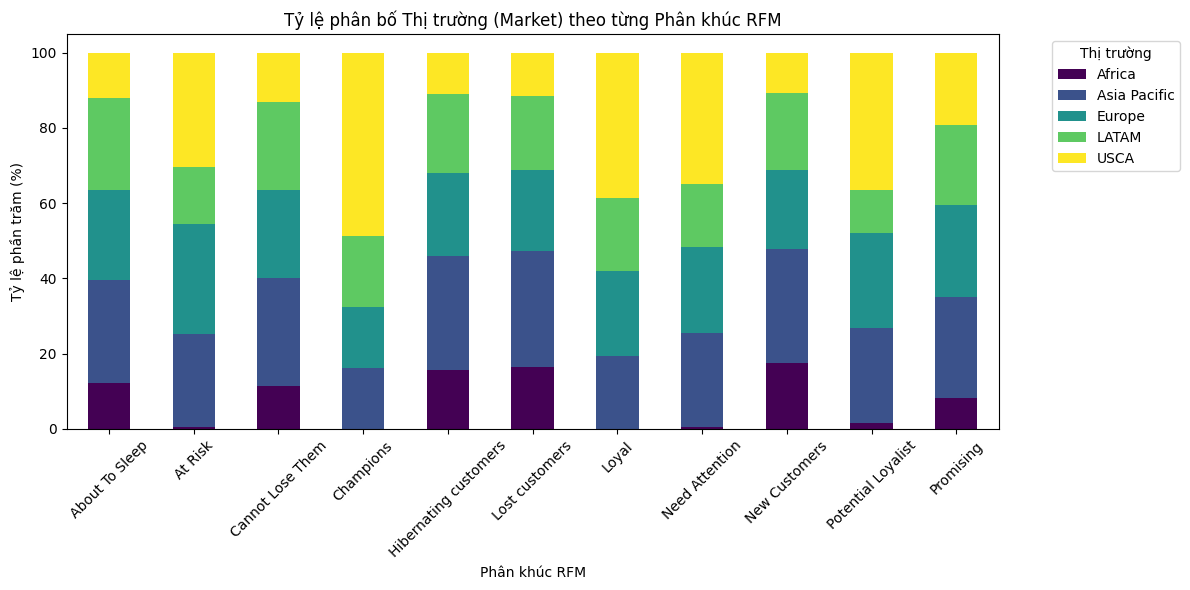

In [ ]:
# Gộp dữ liệu địa lý chi tiết vào bảng tổng hợp theo CustomerID
df_master = pd.merge(df_full_profile, df_geo, on='CustomerID', how='left', suffixes=('', '_master_geo'))
plt.figure(figsize=(12, 6))
# Lập bảng thống kê chéo chéo giữa Segment và Market
market_segment = pd.crosstab(df_master['RFM_Segment'], df_master['Market'], normalize='index') * 100

market_segment.plot(kind='bar', stacked=True, colormap='viridis', figsize=(12, 6))
plt.title('Tỷ lệ phân bố Thị trường (Market) theo từng Phân khúc RFM')
plt.xlabel('Phân khúc RFM')
plt.ylabel('Tỷ lệ phần trăm (%)')
plt.xticks(rotation=45)
plt.legend(title='Thị trường', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
df_master.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17415 entries, 0 to 17414
Data columns (total 27 columns):
 #   Column            Non-Null Count  Dtype   
---  ------            --------------  -----   
 0   CustomerID        17415 non-null  object  
 1   FirstName         17415 non-null  object  
 2   LastName          17415 non-null  object  
 3   BirthDate         17415 non-null  object  
 4   MaritalStatus     17415 non-null  object  
 5   Gender            17291 non-null  object  
 6   EmailAddress      17415 non-null  object  
 7   AnnualIncome      17415 non-null  int64   
 8   EducationLevel    17415 non-null  object  
 9   Occupation        17415 non-null  object  
 10  HomeOwner         17415 non-null  object  
 11  Recency           17415 non-null  int64   
 12  Frequency         17415 non-null  int64   
 13  Monetary          17415 non-null  float64 
 14  R_Score           17415 non-null  category
 15  M_Score           17415 non-null  category
 16  F_Score           1741

**Insight**


*   Các phân khúc quan trọng như Champions, Loyal hay Potential Loyalist thì có số KH ở khu vực USCA chiếm tỉ trọng lớn (~ 40%)
*   Asia Pacific cũng là 1 thị trường đáng kể



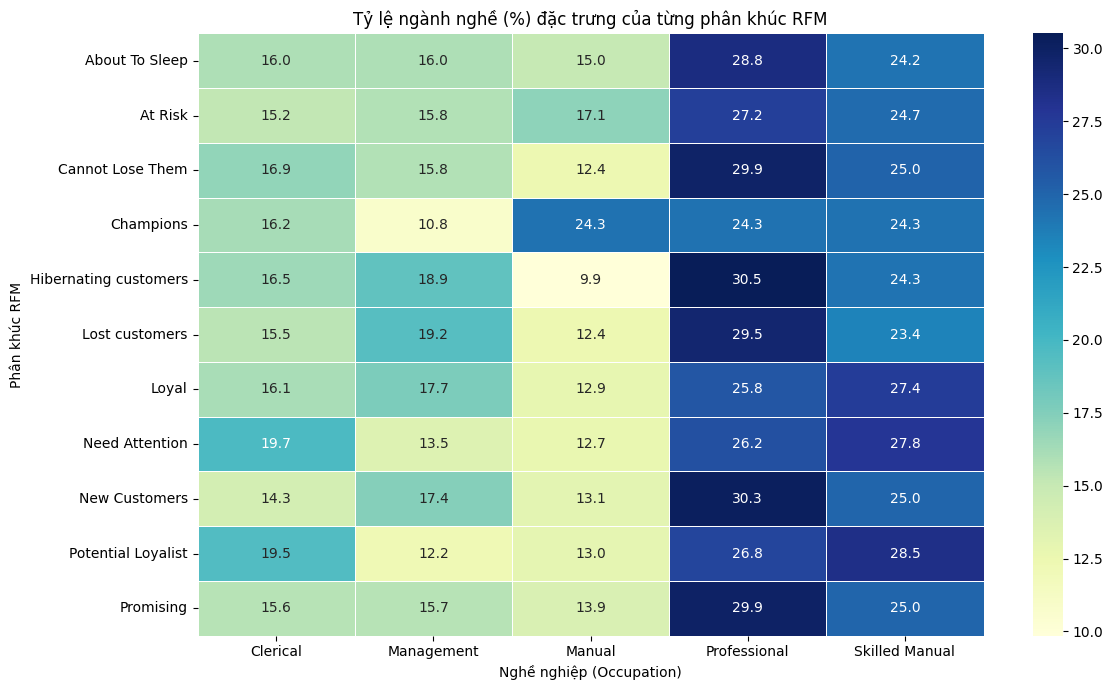

In [ ]:
plt.figure(figsize=(12, 7))
# Tạo bảng chéo hiển thị tỷ lệ % nghề nghiệp trong mỗi phân khúc
occupation_matrix = pd.crosstab(df_master['RFM_Segment'], df_master['Occupation'], normalize='index') * 100

sns.heatmap(occupation_matrix, annot=True, fmt=".1f", cmap="YlGnBu", linewidths=.5)
plt.title('Tỷ lệ ngành nghề (%) đặc trưng của từng phân khúc RFM')
plt.xlabel('Nghề nghiệp (Occupation)')
plt.ylabel('Phân khúc RFM')
plt.tight_layout()
plt.show()




*   Phần lớn KH thuộc nhóm nghề lao động tri thức, có kĩ năng chuyên môn cao (Professional và Skilled Manual)
*   Trong khi Professional chiếm tỉ trọng cao ở hầu hết các phân khúc, thì Skilled Manual nổi bật ở các nhóm khách hàng có tiềm năng và trung thành (Loyal, Need Attention, Potential Loyalist)

* Manual có tỷ trọng thấp ở phần lớn phân khúc, đáng chú ý ở nhóm Champions, tỷ trọng của Manual cao nhất và bằng nhóm Professional, Skilled Manual



/tmp/ipykernel_1512/3509381300.py:4: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1512/3509381300.py:6: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.

/tmp/ipykernel_1512/3509381300.py:14: FutureWarning:



Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.


/tmp/ipykernel_1512/3509381300.py:16: UserWarning:

set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.



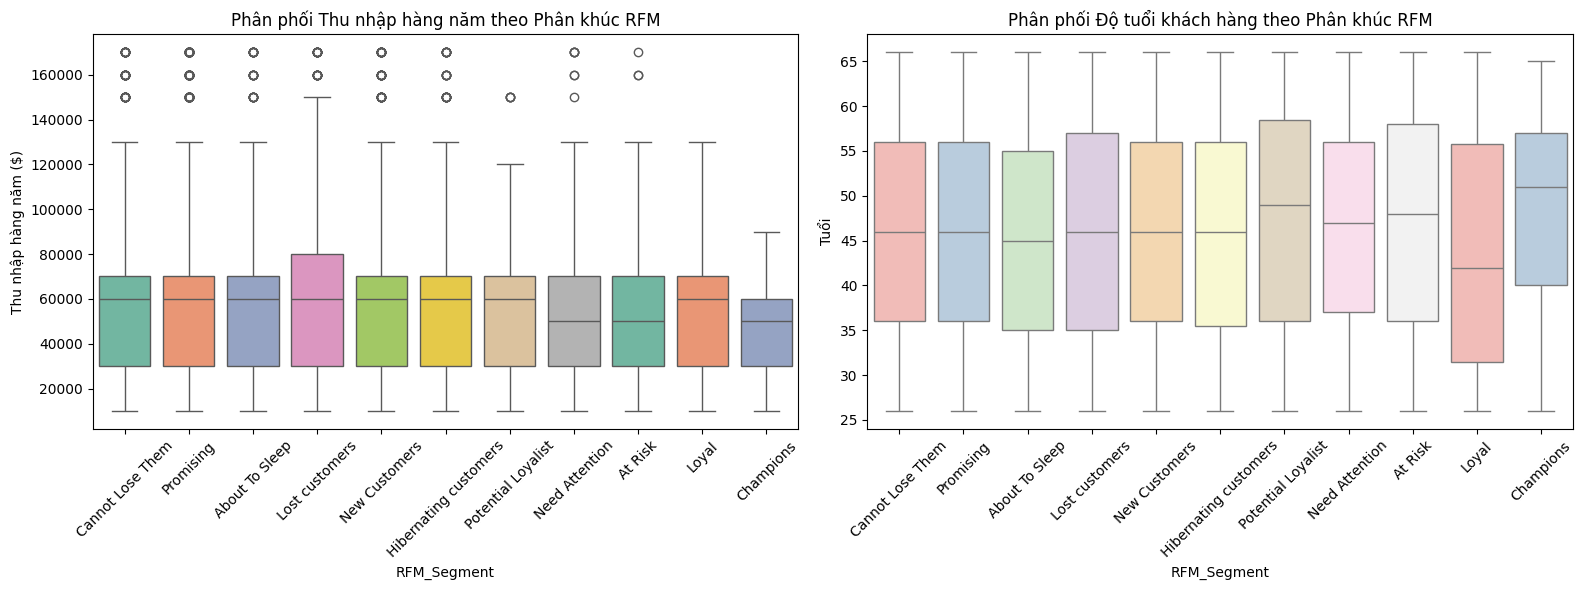

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Vẽ phân phối Thu nhập theo Phân khúc
sns.boxplot(ax=axes[0], data=df_master, x='RFM_Segment', y='AnnualIncome', palette='Set2')
axes[0].set_title('Phân phối Thu nhập hàng năm theo Phân khúc RFM')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=45)
axes[0].set_ylabel('Thu nhập hàng năm ($)')

# Vẽ phân phối Tuổi theo Phân khúc
import datetime
current_year = datetime.datetime.now().year
df_master['Age'] = current_year - pd.to_datetime(df_master['BirthDate']).dt.year

sns.boxplot(ax=axes[1], data=df_master, x='RFM_Segment', y='Age', palette='Pastel1')
axes[1].set_title('Phân phối Độ tuổi khách hàng theo Phân khúc RFM')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=45)
axes[1].set_ylabel('Tuổi')

plt.tight_layout()
plt.show()



*   Thu nhập giữa các phân khúc không có chênh lệch nhiều. Các nhóm Champions, Loyal, At Risk và Need Attention có mức thu nhập trung vị tương đối tương đồng => thu nhập không phải yếu tố duy nhất quyết định mức độ trung thành.
*   Độ tuổi trung vị của phần lớn phân khúc nằm trong khoảng 42–51 tuổi. => sự hiện diện đáng kể của KH trưởng thành


In [ ]:
df_product = ecom_sales.merge(df_rfm, on = 'CustomerID', how = 'left')
df_product = df_product.merge(product, on = 'ProductCode', how = 'left')
df_product.head(5)

,RowID,OrderID,OrderDate,CustomerID,Segment,RegionCode,ProductCode,Quantity,Sales,Discount,...,Frequency,Monetary,R_Score,M_Score,F_Score,RFM_score,RFM_Segment,Product,Category,Subcategory
0,25221,IN-2012-TH211151-41003,4/4/2020,TH-211151,Corporate,RRR0001,P000001,13,416,0.0,...,1,868.0,1,5,1,115,Cannot Lose Them,Soap & Glory Endless Glove Moisturizing Hand C...,Body care,"bath oils, bubbles and soaks"
1,29464,ID-2013-BD116051-41518,9/1/2021,BD-116051,Consumer,R0002,PPP000002,4,20,0.0,...,1,389.0,2,4,1,214,Cannot Lose Them,NaN,NaN,NaN
2,27311,IN-2015-TS212051-42173,6/18/2023,TS-212051,Corporate,R0003,P000003,2,20,0.0,...,1,428.0,4,4,1,414,Promising,Estée Lauder Pure Color Envy Irresistible,Body care,"bath oils, bubbles and soaks"
3,28882,IN-2014-SU206651-41899,9/17/2022,SU-206651,Self-Employed,R0003,P000004,4,556,0.0,...,1,584.0,3,5,1,315,Promising,Gold Infinity Bracelet,Body care,body moisturizers
4,27992,IN-2015-GM144551-42217,8/1/2023,GM-144551,Self-Employed,R0003,P000005,2,6,0.0,...,1,146.0,4,3,1,413,Promising,Deborah Lippmann Nail Polish Lady is a Tramp C...,Body care,body moisturizers


In [ ]:
df_product['Subcategory'].nunique()

17

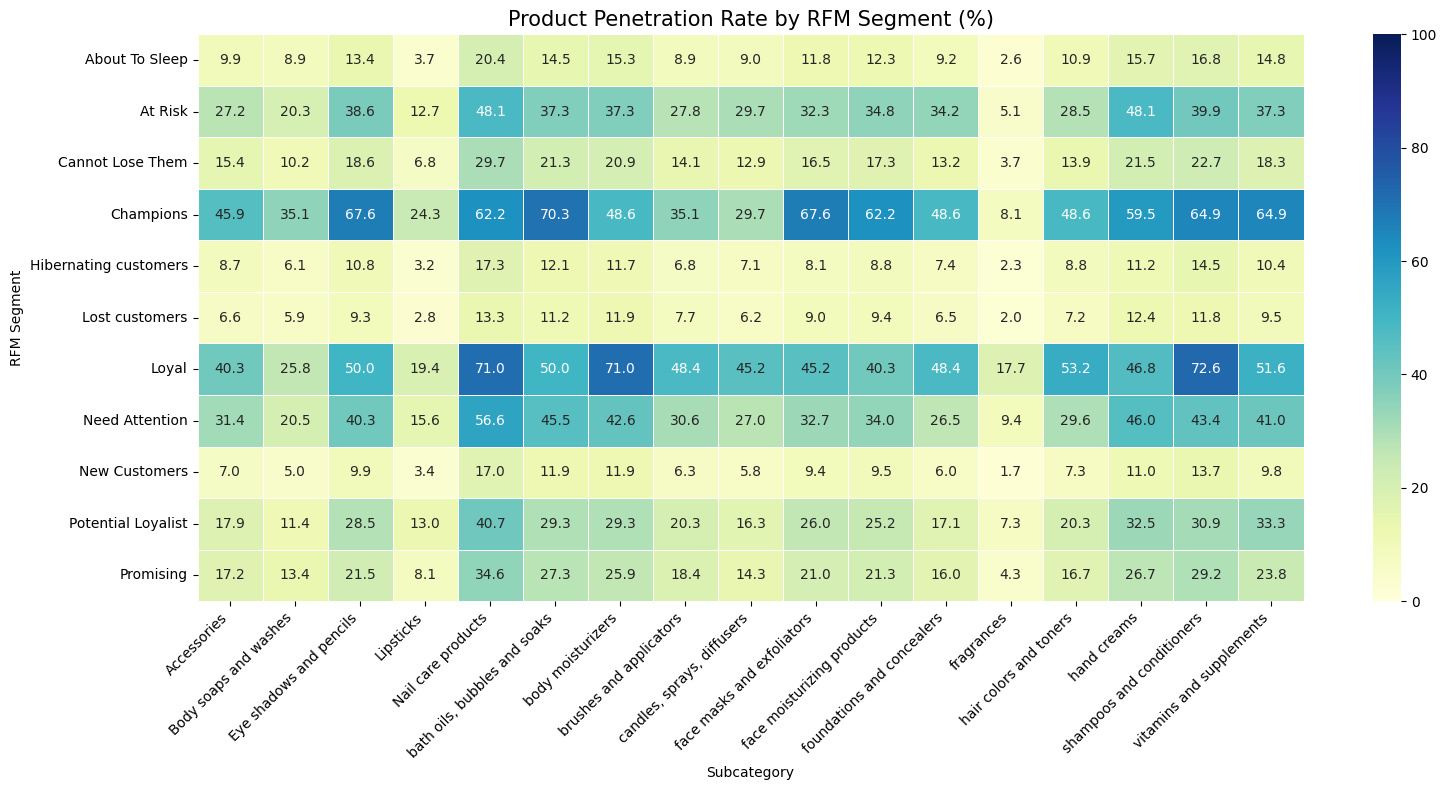

In [ ]:
# Đếm khách hàng duy nhất mua từng Subcategory
customer_product = df_product.drop_duplicates(
    ['CustomerID', 'Subcategory']
)

pivot_customer = pd.crosstab(
    customer_product['RFM_Segment'],
    customer_product['Subcategory']
)

# Tổng số khách hàng duy nhất mỗi Segment
segment_size = df_product.groupby('RFM_Segment')['CustomerID'].nunique()

# Tính tỷ lệ thâm nhập sản phẩm
penetration = pivot_customer.div(
    segment_size, axis=0
) * 100

plt.figure(figsize=(16, 8))

sns.heatmap(
    penetration,
    annot=True,
    fmt='.1f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=100
)

plt.title('Product Penetration Rate by RFM Segment (%)',
          fontsize=15)
plt.xlabel('Subcategory')
plt.ylabel('RFM Segment')

plt.xticks(rotation=45, ha='right')

plt.tight_layout()
plt.show()

**Insight**


*   Champions và Loyal có mức độ thâm nhập sản phẩm cao ở nhiều Subcategory => đây là những nhóm khách hàng có mức độ tương tác và phạm vi mua sắm đa dạng.
* Trong khi đó, Need Attention và At Risk vẫn duy trì sự quan tâm đối với một số danh mục cụ thể (nail care product và hand creams), tạo cơ hội cho các chiến dịch tái kích hoạt cá nhân hóa.

*   Đáng chú ý, Nail care products xuất hiện với tỷ lệ thâm nhập tương đối cao ở nhiều phân khúc, cho thấy đây là một danh mục có độ phủ khách hàng đáng quan tâm. => có thể tận dụng danh mục này để phát triển các chương trình cross-selling và product recommendations.



# Conclusion & Recommendation

In [ ]:
df_rfm.groupby('RFM_Segment').agg(
    customers=('CustomerID', 'nunique'),
    avg_recency=('Recency', 'mean'),
    avg_frequency=('Frequency', 'mean'),
    avg_monetary=('Monetary', 'mean')
).sort_values('avg_monetary', ascending=False)

,customers,avg_recency,avg_frequency,avg_monetary
RFM_Segment,,,,
Loyal,62,1318.887097,5.112903,1680.810742
Champions,37,1133.756757,6.324324,1596.660811
Need Attention,385,1371.057143,3.672727,1006.952930
At Risk,158,1773.379747,3.297468,764.433494
Promising,6169,1256.629924,1.770789,500.443734
Cannot Lose Them,2820,2023.162411,1.186170,493.650671
Potential Loyalist,123,1334.154472,3.138211,150.333886
About To Sleep,1370,1617.108029,1.186131,104.289949
Hibernating customers,1583,1760.607075,1.139608,43.655932


Cần tập trung marketing vào các phân khúc chính, đóng góp doanh thu lớn để tối ưu hóa chi phí
1. Nhóm Champions & Loyal (Trái tim của thương hiệu)

* Chiến lược: Biến họ thành đại sứ thương hiệu và duy trì đặc quyền.
* Hành động:
	* Tặng họ trải nghiệm độc quyền (ví dụ: CSKH riêng, tham gia sự kiện kín, thử nghiệm sản phẩm mới trước khi ra mắt).
  * Tạo chương trình giới thiệu (Referral Program) để họ kéo thêm bạn bè có hành vi mua sắm tương tự vào hệ thống.

2. Nhóm Promising (Động cơ đẩy quy mô)

* Chiến lược: Nâng cấp họ lên nhóm Loyal.
* Hành động: Vì tần suất mua của họ mới ở mức trung bình, cần thiết lập các cột mốc chi tiêu hoặc số lần mua (ví dụ: "Mua thêm 2 đơn hàng để thăng hạng Loyal"). Việc này sẽ tận dụng lợi thế số lượng lớn của họ để đẩy tổng doanh thu.

3. Nhóm Cannot Lose Them

* có mức chi tiêu trên mỗi khách hàng (AOV) cao. Tuy nhiên, đã ngừng hoặc giảm mua đáng kể.
* Hành động: cần kích cầu, tái khởi động lại nhóm này sớm